In [1]:
# Local macOS edition. See LOCAL-SETUP.md. Definitions for spawn workers live in drl_book/.
# DDPG, TD3, SAC, PPO

In [2]:
import torch
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available(), "MPS:", torch.backends.mps.is_available())

PyTorch: 2.15.0
CUDA: False MPS: True


In [3]:
import warnings ; warnings.filterwarnings('ignore')
import os
os.environ['CUDA_DEVICE_ORDER']='PCI_BUS_ID'
os.environ['OMP_NUM_THREADS'] = '1'

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.multiprocessing as mp
import threading
from torch.distributions import Normal

import numpy as np
from IPython.display import display
from collections import namedtuple, deque
import matplotlib.pyplot as plt
import matplotlib.pylab as pylab
from itertools import cycle, count
from textwrap import wrap

import pybullet_envs
import matplotlib
import subprocess
import os.path
import tempfile
import random
import base64
import pprint
import glob
import time
import json
import sys
import gym
import io
import os
import gc

from gym import wrappers
from skimage.transform import resize
from skimage.color import rgb2gray
from subprocess import check_output
from IPython.display import display, HTML

LEAVE_PRINT_EVERY_N_SECS = 300
ERASE_LINE = '\x1b[2K'
EPS = 1e-6
BEEP = lambda: os.system("printf '\a'")
RESULTS_DIR = os.path.join('..', 'results')
SEEDS = (12, 34, 56, 78, 90)

%matplotlib inline

In [4]:
plt.style.use('fivethirtyeight')
params = {
    'figure.figsize': (15, 8),
    'font.size': 24,
    'legend.fontsize': 20,
    'axes.titlesize': 28,
    'axes.labelsize': 24,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20
}
pylab.rcParams.update(params)
np.set_printoptions(suppress=True)

In [5]:
torch.cuda.is_available()

False

In [6]:
from drl_book.chapter12 import get_make_env_fn

In [7]:
from drl_book.chapter12 import get_videos_html

In [8]:
from drl_book.chapter12 import get_gif_html

In [9]:
from drl_book.chapter12 import RenderUint8

# DDPG

In [10]:
from drl_book.chapter12 import FCQV

In [11]:
from drl_book.chapter12 import FCDP

In [12]:
from drl_book.chapter12 import ReplayBuffer

In [13]:
from drl_book.chapter12 import GreedyStrategy

In [14]:
from drl_book.chapter12 import NormalNoiseStrategy

In [15]:
from drl_book.chapter12 import DDPG

In [16]:
ddpg_results = []
best_agent, best_eval_score = None, float('-inf')
for seed in SEEDS:
    environment_settings = {
        'env_name': 'Pendulum-v0',
        'gamma': 0.99,
        'max_minutes': 20,
        'max_episodes': 500,
        'goal_mean_100_reward': -150
    }

    policy_model_fn = lambda nS, bounds: FCDP(nS, bounds, hidden_dims=(256,256))
    policy_max_grad_norm = float('inf')
    policy_optimizer_fn = lambda net, lr: optim.Adam(net.parameters(), lr=lr)
    policy_optimizer_lr = 0.0003

    value_model_fn = lambda nS, nA: FCQV(nS, nA, hidden_dims=(256,256))
    value_max_grad_norm = float('inf')
    value_optimizer_fn = lambda net, lr: optim.Adam(net.parameters(), lr=lr)
    value_optimizer_lr = 0.0003

    training_strategy_fn = lambda bounds: NormalNoiseStrategy(bounds, exploration_noise_ratio=0.1)
    evaluation_strategy_fn = lambda bounds: GreedyStrategy(bounds)

    replay_buffer_fn = lambda: ReplayBuffer(max_size=100000, batch_size=256)
    n_warmup_batches = 5
    update_target_every_steps = 1
    tau = 0.005
    
    env_name, gamma, max_minutes, \
    max_episodes, goal_mean_100_reward = environment_settings.values()

    agent = DDPG(replay_buffer_fn,
                 policy_model_fn, 
                 policy_max_grad_norm, 
                 policy_optimizer_fn, 
                 policy_optimizer_lr,
                 value_model_fn, 
                 value_max_grad_norm, 
                 value_optimizer_fn, 
                 value_optimizer_lr, 
                 training_strategy_fn,
                 evaluation_strategy_fn,
                 n_warmup_batches,
                 update_target_every_steps,
                 tau)

    make_env_fn, make_env_kargs = get_make_env_fn(env_name=env_name)
    result, final_eval_score, training_time, wallclock_time = agent.train(
        make_env_fn, make_env_kargs, seed, gamma, max_minutes, max_episodes, goal_mean_100_reward)
    ddpg_results.append(result)
    if final_eval_score > best_eval_score:
        best_eval_score = final_eval_score
        best_agent = agent
ddpg_results = np.array(ddpg_results)
_ = BEEP()

el 00:00:01, ep 0000, ts 0000200, ar 10 -1296.7±000.0, 100 -1296.7±000.0, ex 100 0.3±0.0, ev -1391.7±000.0
el 00:00:56, ep 0116, ts 0023400, ar 10 -148.8±070.8, 100 -177.3±174.3, ex 100 0.0±0.0, ev -145.3±096.0
--> reached_goal_mean_reward ✓
Training complete.
Final evaluation score -130.96±76.95 in 54.41s training time, 57.53s wall-clock time.

el 00:00:00, ep 0000, ts 0000200, ar 10 -1373.7±000.0, 100 -1373.7±000.0, ex 100 0.3±0.0, ev -1743.3±000.0
el 00:00:57, ep 0121, ts 0024400, ar 10 -145.4±104.7, 100 -140.4±089.8, ex 100 0.0±0.0, ev -149.9±089.0
--> reached_goal_mean_reward ✓
Training complete.
Final evaluation score -148.54±80.22 in 55.88s training time, 58.09s wall-clock time.

el 00:00:00, ep 0000, ts 0000200, ar 10 -1364.0±000.0, 100 -1364.0±000.0, ex 100 0.3±0.0, ev -1923.0±000.0
el 00:02:26, ep 0283, ts 0056800, ar 10 -180.9±076.8, 100 -154.0±091.7, ex 100 0.0±0.0, ev -149.9±090.6
--> reached_goal_mean_reward ✓
Training complete.
Final evaluation score -135.71±77.90 in 143

ffmpeg version 9.0.2 Copyright (c) 2000-2026 the FFmpeg developers
  built with Apple clang version 21.0.0 (clang-2100.3.34.2)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/9.0.2 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags= --enable-ffplay --enable-gpl --enable-libsvtav1 --enable-libopus --enable-libx264 --enable-libmp3lame --enable-libdav1d --enable-libvmaf --enable-libvpx --enable-libx265 --enable-openssl --enable-videotoolbox --enable-audiotoolbox --enable-neon
  libavutil      61.  1.102 / 61.  1.102
  libavcodec     63.  1.102 / 63.  1.102
  libavformat    63.  1.102 / 63.  1.102
  libavdevice    63.  1.102 / 63.  1.102
  libavfilter    12.  1.102 / 12.  1.102
  libswscale     10.  1.102 / 10.  1.102
  libswresample   7.  1.102 /  7.  1.102
Input #0, mov,mp4,m4a,3gp,3g2,mj2, from '/var/folders/cb/44kyj2_d54s23xt17zgqkt_m0000gn/T/tmpehseyxlp/openaigym.video.0.88879.video000000.mp4':
  Metadata:
    major_brand     : isom
    


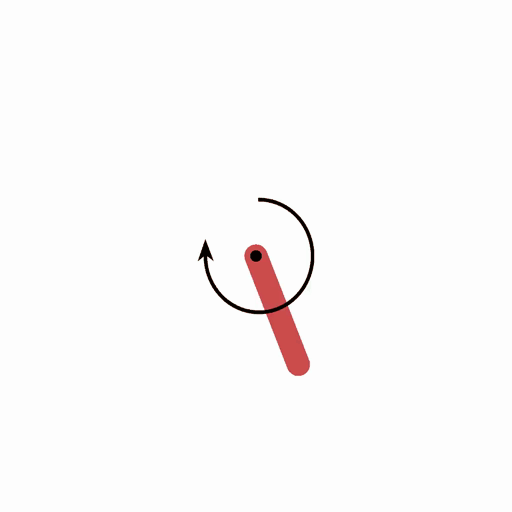
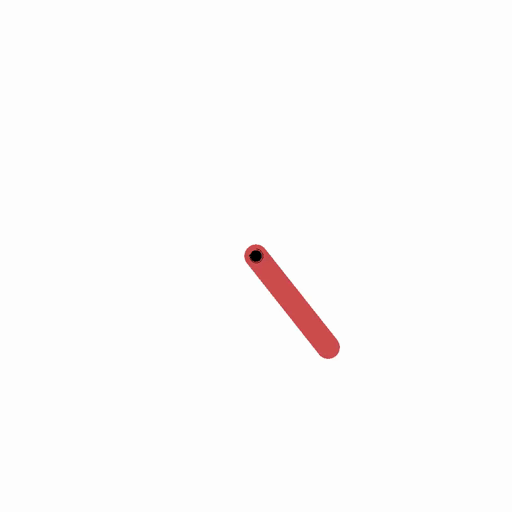
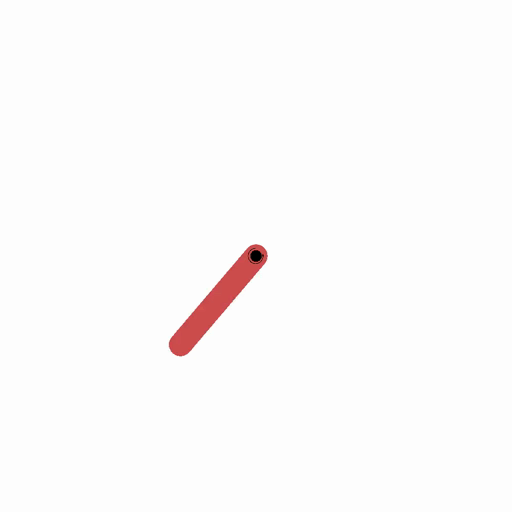
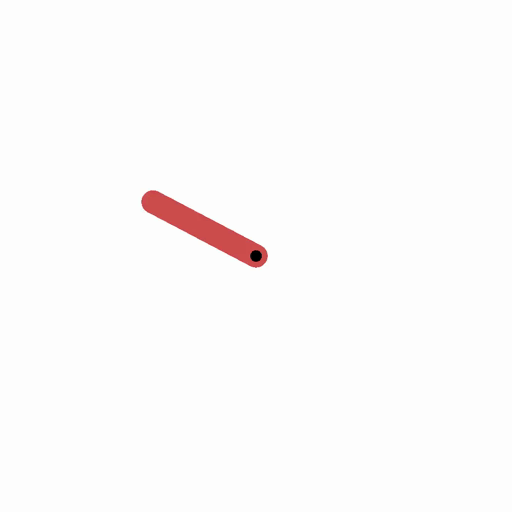

In [17]:
best_agent.demo_progression()


ffmpeg version 9.0.2 Copyright (c) 2000-2026 the FFmpeg developers
  built with Apple clang version 21.0.0 (clang-2100.3.34.2)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/9.0.2 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags= --enable-ffplay --enable-gpl --enable-libsvtav1 --enable-libopus --enable-libx264 --enable-libmp3lame --enable-libdav1d --enable-libvmaf --enable-libvpx --enable-libx265 --enable-openssl --enable-videotoolbox --enable-audiotoolbox --enable-neon
  libavutil      61.  1.102 / 61.  1.102
  libavcodec     63.  1.102 / 63.  1.102
  libavformat    63.  1.102 / 63.  1.102
  libavdevice    63.  1.102 / 63.  1.102
  libavfilter    12.  1.102 / 12.  1.102
  libswscale     10.  1.102 / 10.  1.102
  libswresample   7.  1.102 /  7.  1.102
Input #0, mov,mp4,m4a,3gp,3g2,mj2, from '/var/folders/cb/44kyj2_d54s23xt17zgqkt_m0000gn/T/tmp_5oer06q/openaigym.video.1.88879.video000000.mp4':
  Metadata:
    major_brand     : isom
   


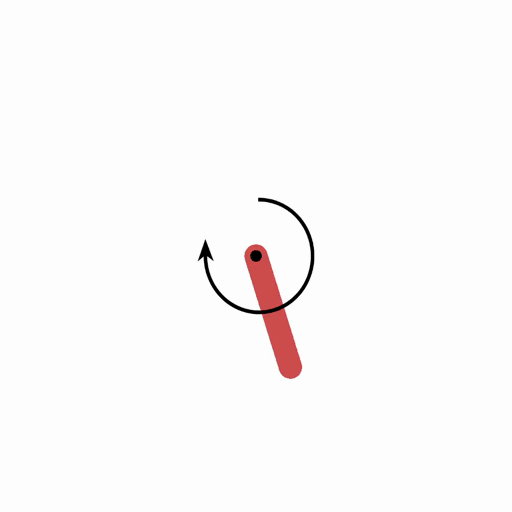
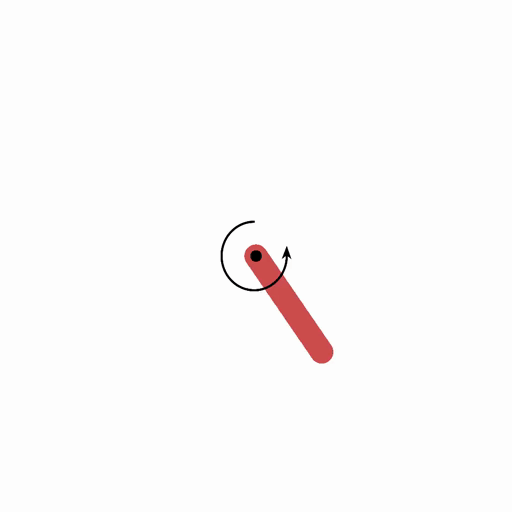

In [18]:
best_agent.demo_last()

In [19]:
ddpg_max_t, ddpg_max_r, ddpg_max_s, \
ddpg_max_sec, ddpg_max_rt = np.max(ddpg_results, axis=0).T
ddpg_min_t, ddpg_min_r, ddpg_min_s, \
ddpg_min_sec, ddpg_min_rt = np.min(ddpg_results, axis=0).T
ddpg_mean_t, ddpg_mean_r, ddpg_mean_s, \
ddpg_mean_sec, ddpg_mean_rt = np.mean(ddpg_results, axis=0).T
ddpg_x = np.arange(len(ddpg_mean_s))

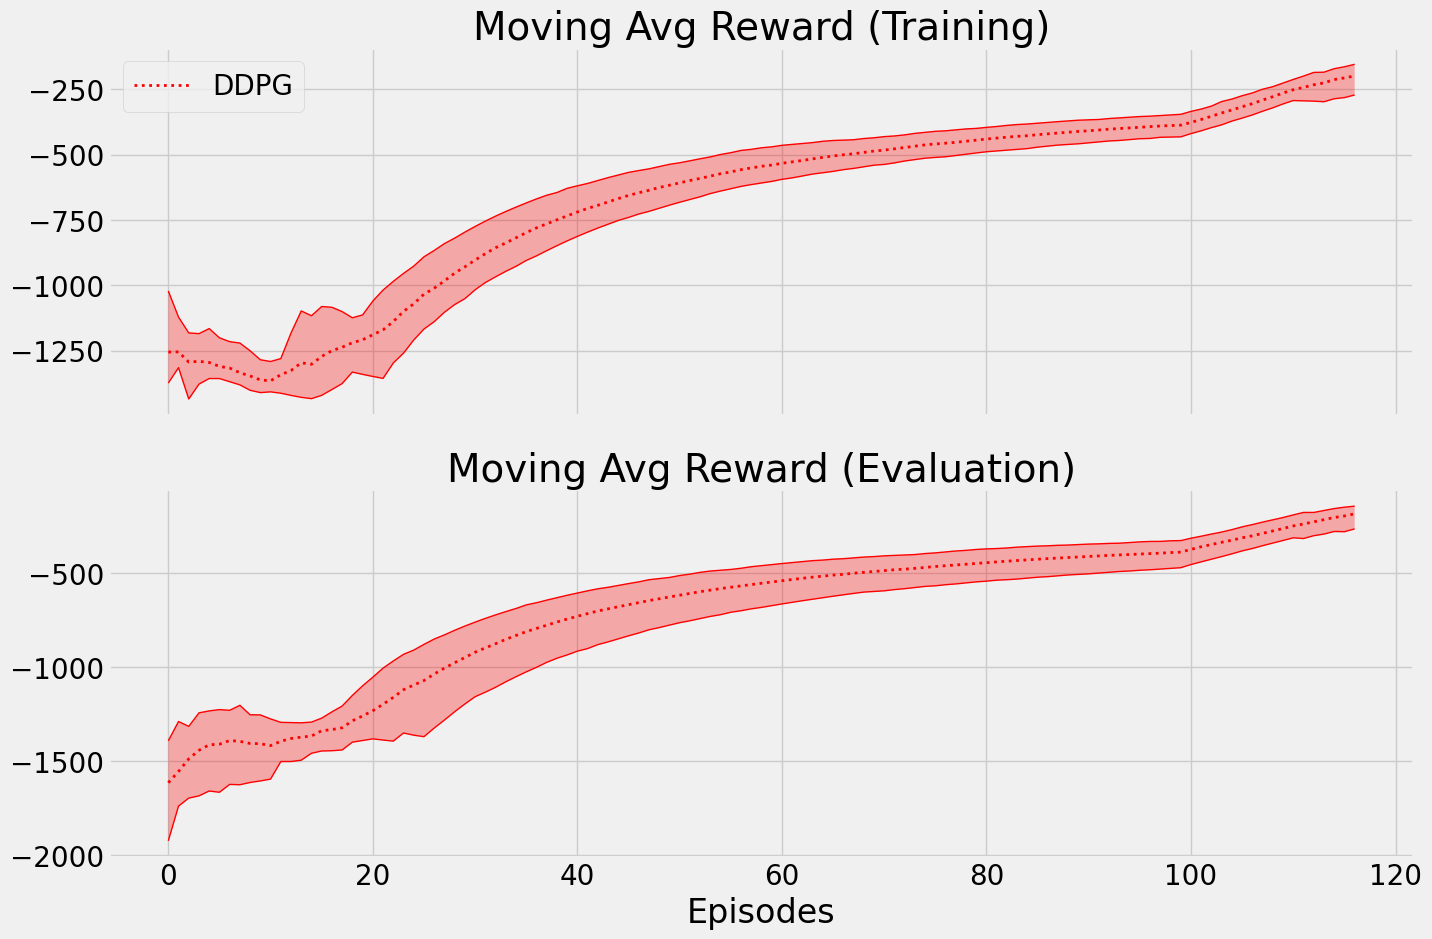

In [20]:
fig, axs = plt.subplots(2, 1, figsize=(15,10), sharey=False, sharex=True)

# DDPG
axs[0].plot(ddpg_max_r, 'r', linewidth=1)
axs[0].plot(ddpg_min_r, 'r', linewidth=1)
axs[0].plot(ddpg_mean_r, 'r:', label='DDPG', linewidth=2)
axs[0].fill_between(
    ddpg_x, ddpg_min_r, ddpg_max_r, facecolor='r', alpha=0.3)

axs[1].plot(ddpg_max_s, 'r', linewidth=1)
axs[1].plot(ddpg_min_s, 'r', linewidth=1)
axs[1].plot(ddpg_mean_s, 'r:', label='DDPG', linewidth=2)
axs[1].fill_between(
    ddpg_x, ddpg_min_s, ddpg_max_s, facecolor='r', alpha=0.3)

# ALL
axs[0].set_title('Moving Avg Reward (Training)')
axs[1].set_title('Moving Avg Reward (Evaluation)')
plt.xlabel('Episodes')
axs[0].legend(loc='upper left')
plt.show()

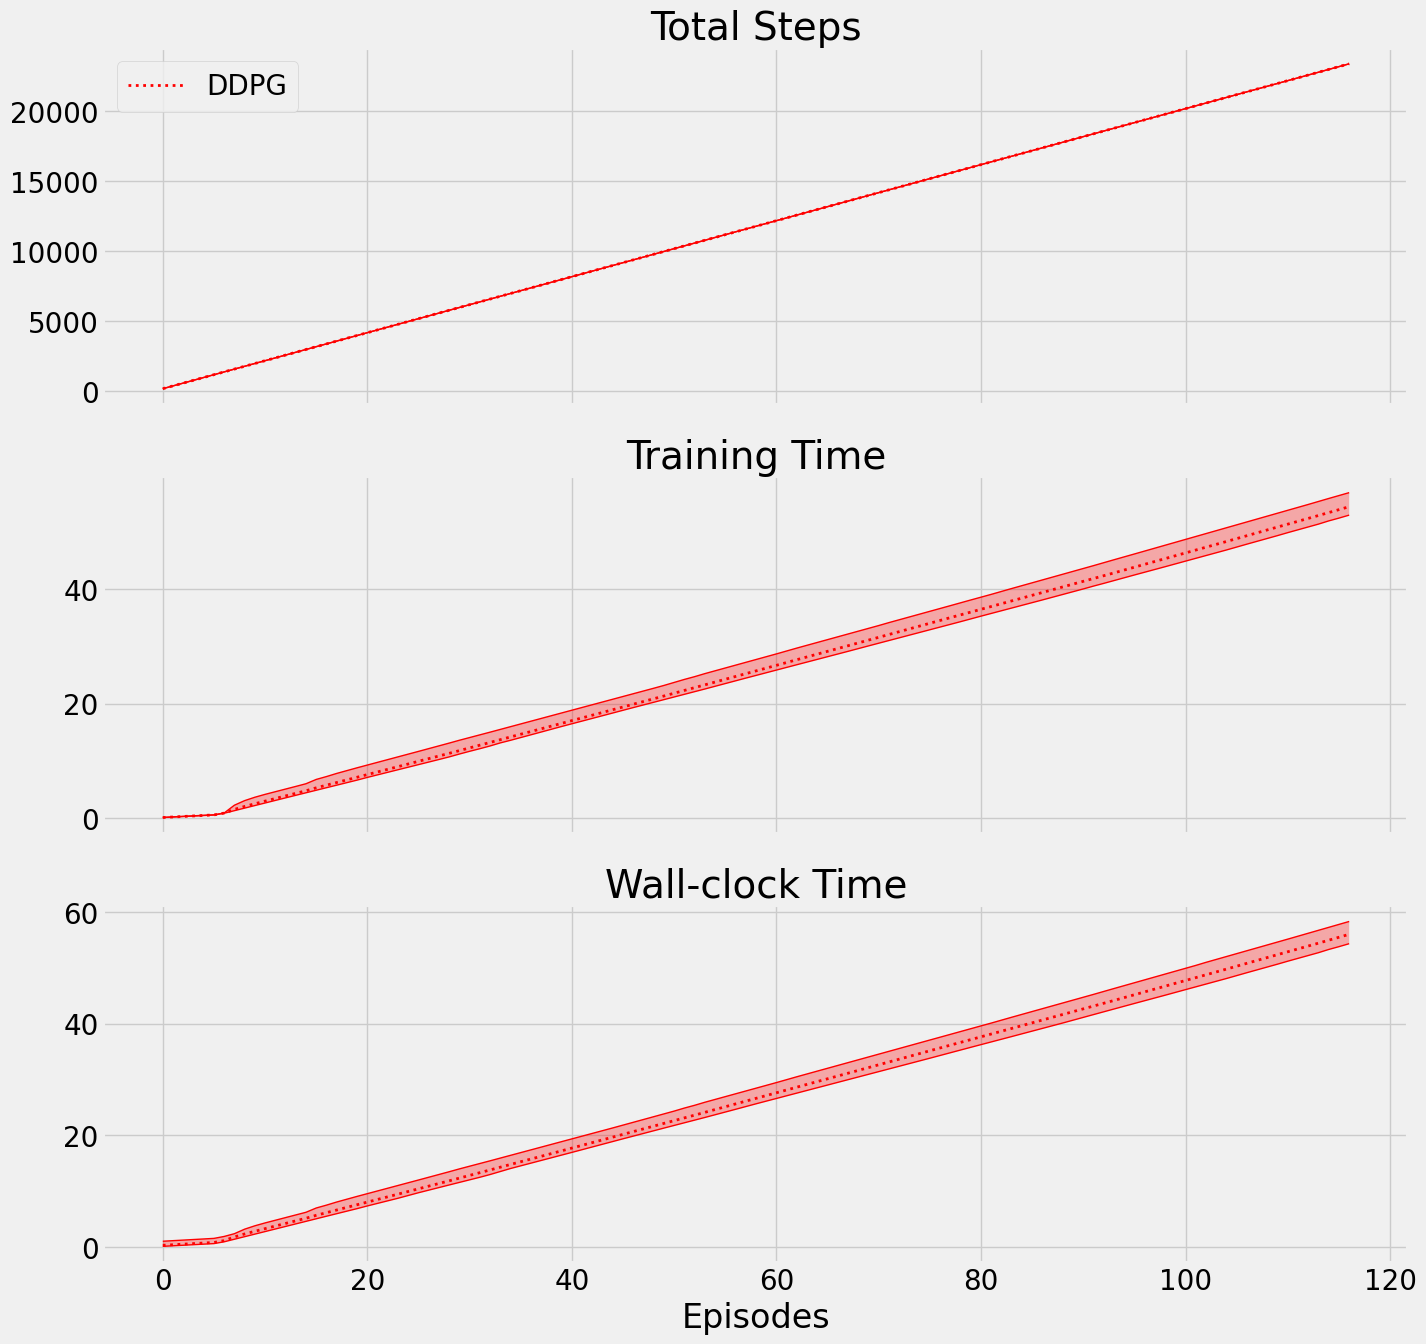

In [21]:
fig, axs = plt.subplots(3, 1, figsize=(15,15), sharey=False, sharex=True)

# DDPG
axs[0].plot(ddpg_max_t, 'r', linewidth=1)
axs[0].plot(ddpg_min_t, 'r', linewidth=1)
axs[0].plot(ddpg_mean_t, 'r:', label='DDPG', linewidth=2)
axs[0].fill_between(
    ddpg_x, ddpg_min_t, ddpg_max_t, facecolor='r', alpha=0.3)

axs[1].plot(ddpg_max_sec, 'r', linewidth=1)
axs[1].plot(ddpg_min_sec, 'r', linewidth=1)
axs[1].plot(ddpg_mean_sec, 'r:', label='DDPG', linewidth=2)
axs[1].fill_between(
    ddpg_x, ddpg_min_sec, ddpg_max_sec, facecolor='r', alpha=0.3)

axs[2].plot(ddpg_max_rt, 'r', linewidth=1)
axs[2].plot(ddpg_min_rt, 'r', linewidth=1)
axs[2].plot(ddpg_mean_rt, 'r:', label='DDPG', linewidth=2)
axs[2].fill_between(
    ddpg_x, ddpg_min_rt, ddpg_max_rt, facecolor='r', alpha=0.3)

# ALL
axs[0].set_title('Total Steps')
axs[1].set_title('Training Time')
axs[2].set_title('Wall-clock Time')
plt.xlabel('Episodes')
axs[0].legend(loc='upper left')
plt.show()

In [22]:
ddpg_root_dir = os.path.join(RESULTS_DIR, 'ddpg')
not os.path.exists(ddpg_root_dir) and os.makedirs(ddpg_root_dir)

np.save(os.path.join(ddpg_root_dir, 'x'), ddpg_x)

np.save(os.path.join(ddpg_root_dir, 'max_r'), ddpg_max_r)
np.save(os.path.join(ddpg_root_dir, 'min_r'), ddpg_min_r)
np.save(os.path.join(ddpg_root_dir, 'mean_r'), ddpg_mean_r)

np.save(os.path.join(ddpg_root_dir, 'max_s'), ddpg_max_s)
np.save(os.path.join(ddpg_root_dir, 'min_s'), ddpg_min_s )
np.save(os.path.join(ddpg_root_dir, 'mean_s'), ddpg_mean_s)

np.save(os.path.join(ddpg_root_dir, 'max_t'), ddpg_max_t)
np.save(os.path.join(ddpg_root_dir, 'min_t'), ddpg_min_t)
np.save(os.path.join(ddpg_root_dir, 'mean_t'), ddpg_mean_t)

np.save(os.path.join(ddpg_root_dir, 'max_sec'), ddpg_max_sec)
np.save(os.path.join(ddpg_root_dir, 'min_sec'), ddpg_min_sec)
np.save(os.path.join(ddpg_root_dir, 'mean_sec'), ddpg_mean_sec)

np.save(os.path.join(ddpg_root_dir, 'max_rt'), ddpg_max_rt)
np.save(os.path.join(ddpg_root_dir, 'min_rt'), ddpg_min_rt)
np.save(os.path.join(ddpg_root_dir, 'mean_rt'), ddpg_mean_rt)

# TD3

In [23]:
from drl_book.chapter12 import NormalNoiseDecayStrategy

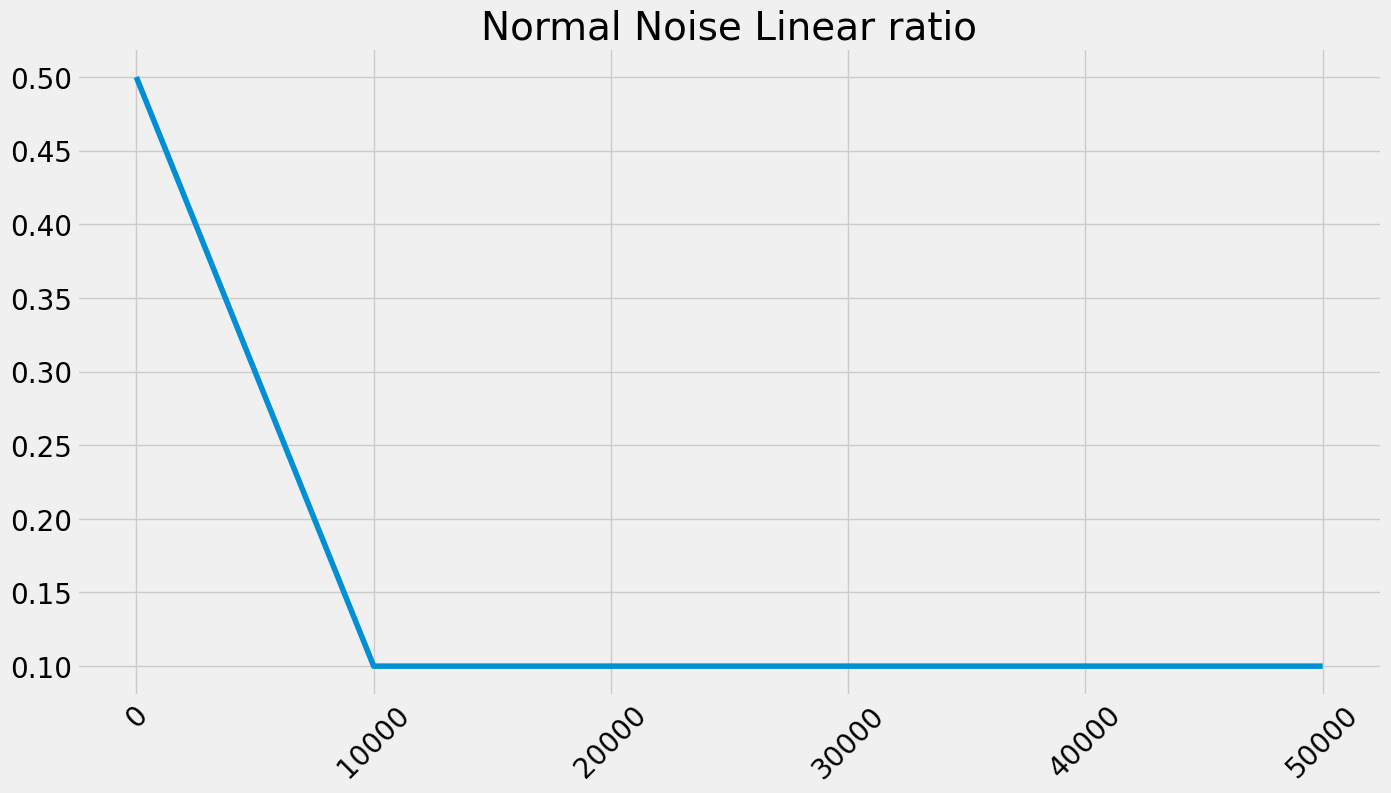

In [24]:
s = NormalNoiseDecayStrategy(([-2],[2]))
plt.plot([s._noise_ratio_update() for _ in range(50000)])
plt.title('Normal Noise Linear ratio')
plt.xticks(rotation=45)
plt.show()

In [25]:
from drl_book.chapter12 import FCTQV

In [26]:
from drl_book.chapter12 import TD3

In [ ]:
td3_results = []
best_agent, best_eval_score = None, float('-inf')
for seed in SEEDS:
    environment_settings = {
        'env_name': 'HopperBulletEnv-v0',
        'gamma': 0.99,
        'max_minutes': 300,
        'max_episodes': 10000,
        'goal_mean_100_reward': 1500
    }
    
    policy_model_fn = lambda nS, bounds: FCDP(nS, bounds, hidden_dims=(256,256))
    policy_max_grad_norm = float('inf')
    policy_optimizer_fn = lambda net, lr: optim.Adam(net.parameters(), lr=lr)
    policy_optimizer_lr = 0.0003

    value_model_fn = lambda nS, nA: FCTQV(nS, nA, hidden_dims=(256,256))
    value_max_grad_norm = float('inf')
    value_optimizer_fn = lambda net, lr: optim.Adam(net.parameters(), lr=lr)
    value_optimizer_lr = 0.0003

    training_strategy_fn = lambda bounds: NormalNoiseDecayStrategy(bounds,
                                                                   init_noise_ratio=0.5,
                                                                   min_noise_ratio=0.1,
                                                                   decay_steps=200000)
    evaluation_strategy_fn = lambda bounds: GreedyStrategy(bounds)

    replay_buffer_fn = lambda: ReplayBuffer(max_size=1000000, batch_size=256)
    n_warmup_batches = 5
    update_value_target_every_steps = 2
    update_policy_target_every_steps = 2
    train_policy_every_steps = 2
    policy_noise_ratio = 0.1
    policy_noise_clip_ratio = 0.5
    tau = 0.005

    env_name, gamma, max_minutes, \
    max_episodes, goal_mean_100_reward = environment_settings.values()

    agent = TD3(replay_buffer_fn,
                policy_model_fn, 
                policy_max_grad_norm, 
                policy_optimizer_fn, 
                policy_optimizer_lr,
                value_model_fn,
                value_max_grad_norm, 
                value_optimizer_fn, 
                value_optimizer_lr, 
                training_strategy_fn,
                evaluation_strategy_fn,
                n_warmup_batches,
                update_value_target_every_steps,
                update_policy_target_every_steps,
                train_policy_every_steps,
                tau,
                policy_noise_ratio,
                policy_noise_clip_ratio)

    make_env_fn, make_env_kargs = get_make_env_fn(env_name=env_name, inner_wrappers=[RenderUint8])
    result, final_eval_score, training_time, wallclock_time = agent.train(
        make_env_fn, make_env_kargs, seed, gamma, max_minutes, max_episodes, goal_mean_100_reward)
    td3_results.append(result)
    if final_eval_score > best_eval_score:
        best_eval_score = final_eval_score
        best_agent = agent
td3_results = np.array(td3_results)
_ = BEEP()

pybullet build time: Oct 31 2026 08:21:27


argv[0]=
argv[0]=
el 00:00:00, ep 0000, ts 0000009, ar 10 011.6±000.0, 100 011.6±000.0, ex 100 0.4±0.0, ev 035.5±000.0
el 00:05:00, ep 1412, ts 0067419, ar 10 145.7±105.7, 100 132.9±091.5, ex 100 0.1±0.0, ev 782.9±258.5


In [ ]:
best_agent.demo_progression()

In [ ]:
best_agent.demo_last()

In [ ]:
stop

In [ ]:
td3_max_t, td3_max_r, td3_max_s, \
td3_max_sec, td3_max_rt = np.max(td3_results, axis=0).T
td3_min_t, td3_min_r, td3_min_s, \
td3_min_sec, td3_min_rt = np.min(td3_results, axis=0).T
td3_mean_t, td3_mean_r, td3_mean_s, \
td3_mean_sec, td3_mean_rt = np.mean(td3_results, axis=0).T
td3_x = np.arange(len(td3_mean_s))

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(15,10), sharey=False, sharex=True)

# TD3
axs[0].plot(td3_max_r, 'b', linewidth=1)
axs[0].plot(td3_min_r, 'b', linewidth=1)
axs[0].plot(td3_mean_r, 'b:', label='TD3', linewidth=2)
axs[0].fill_between(
    td3_x, td3_min_r, td3_max_r, facecolor='b', alpha=0.3)

axs[1].plot(td3_max_s, 'b', linewidth=1)
axs[1].plot(td3_min_s, 'b', linewidth=1)
axs[1].plot(td3_mean_s, 'b:', label='TD3', linewidth=2)
axs[1].fill_between(
    td3_x, td3_min_s, td3_max_s, facecolor='b', alpha=0.3)

# ALL
axs[0].set_title('Moving Avg Reward (Training)')
axs[1].set_title('Moving Avg Reward (Evaluation)')
plt.xlabel('Episodes')
axs[0].legend(loc='upper left')
plt.show()

In [ ]:
fig, axs = plt.subplots(3, 1, figsize=(15,15), sharey=False, sharex=True)

# TD3
axs[0].plot(td3_max_t, 'b', linewidth=1)
axs[0].plot(td3_min_t, 'b', linewidth=1)
axs[0].plot(td3_mean_t, 'b:', label='TD3', linewidth=2)
axs[0].fill_between(
    td3_x, td3_min_t, td3_max_t, facecolor='b', alpha=0.3)

axs[1].plot(td3_max_sec, 'b', linewidth=1)
axs[1].plot(td3_min_sec, 'b', linewidth=1)
axs[1].plot(td3_mean_sec, 'b:', label='TD3', linewidth=2)
axs[1].fill_between(
    td3_x, td3_min_sec, td3_max_sec, facecolor='b', alpha=0.3)

axs[2].plot(td3_max_rt, 'b', linewidth=1)
axs[2].plot(td3_min_rt, 'b', linewidth=1)
axs[2].plot(td3_mean_rt, 'b:', label='TD3', linewidth=2)
axs[2].fill_between(
    td3_x, td3_min_rt, td3_max_rt, facecolor='b', alpha=0.3)

# ALL
axs[0].set_title('Total Steps')
axs[1].set_title('Training Time')
axs[2].set_title('Wall-clock Time')
plt.xlabel('Episodes')
axs[0].legend(loc='upper left')
plt.show()

In [ ]:
td3_root_dir = os.path.join(RESULTS_DIR, 'td3')
not os.path.exists(td3_root_dir) and os.makedirs(td3_root_dir)

np.save(os.path.join(td3_root_dir, 'x'), td3_x)

np.save(os.path.join(td3_root_dir, 'max_r'), td3_max_r)
np.save(os.path.join(td3_root_dir, 'min_r'), td3_min_r)
np.save(os.path.join(td3_root_dir, 'mean_r'), td3_mean_r)

np.save(os.path.join(td3_root_dir, 'max_s'), td3_max_s)
np.save(os.path.join(td3_root_dir, 'min_s'), td3_min_s )
np.save(os.path.join(td3_root_dir, 'mean_s'), td3_mean_s)

np.save(os.path.join(td3_root_dir, 'max_t'), td3_max_t)
np.save(os.path.join(td3_root_dir, 'min_t'), td3_min_t)
np.save(os.path.join(td3_root_dir, 'mean_t'), td3_mean_t)

np.save(os.path.join(td3_root_dir, 'max_sec'), td3_max_sec)
np.save(os.path.join(td3_root_dir, 'min_sec'), td3_min_sec)
np.save(os.path.join(td3_root_dir, 'mean_sec'), td3_mean_sec)

np.save(os.path.join(td3_root_dir, 'max_rt'), td3_max_rt)
np.save(os.path.join(td3_root_dir, 'min_rt'), td3_min_rt)
np.save(os.path.join(td3_root_dir, 'mean_rt'), td3_mean_rt)

# SAC

In [ ]:
from drl_book.chapter12 import FCQSA

In [ ]:
from drl_book.chapter12 import FCGP

In [ ]:
from drl_book.chapter12 import SAC

In [ ]:
sac_results = []
best_agent, best_eval_score = None, float('-inf')
for seed in SEEDS:
    environment_settings = {
        'env_name': 'HalfCheetahBulletEnv-v0',
        'gamma': 0.99,
        'max_minutes': 300,
        'max_episodes': 10000,
        'goal_mean_100_reward': 2000
    }

    policy_model_fn = lambda nS, bounds: FCGP(nS, bounds, hidden_dims=(256,256))
    policy_max_grad_norm = float('inf')
    policy_optimizer_fn = lambda net, lr: optim.Adam(net.parameters(), lr=lr)
    policy_optimizer_lr = 0.0005

    value_model_fn = lambda nS, nA: FCQSA(nS, nA, hidden_dims=(256,256))
    value_max_grad_norm = float('inf')
    value_optimizer_fn = lambda net, lr: optim.Adam(net.parameters(), lr=lr)
    value_optimizer_lr = 0.0007

    replay_buffer_fn = lambda: ReplayBuffer(max_size=1000000, batch_size=256)
    n_warmup_batches = 10
    update_target_every_steps = 1
    tau = 0.005

    env_name, gamma, max_minutes, \
    max_episodes, goal_mean_100_reward = environment_settings.values()
                
    agent = SAC(replay_buffer_fn,
                policy_model_fn, 
                policy_max_grad_norm,
                policy_optimizer_fn, 
                policy_optimizer_lr,
                value_model_fn,
                value_max_grad_norm, 
                value_optimizer_fn, 
                value_optimizer_lr, 
                n_warmup_batches,
                update_target_every_steps,
                tau)

    make_env_fn, make_env_kargs = get_make_env_fn(env_name=env_name, inner_wrappers=[RenderUint8])
    result, final_eval_score, training_time, wallclock_time = agent.train(
        make_env_fn, make_env_kargs, seed, gamma, max_minutes, max_episodes, goal_mean_100_reward)
    sac_results.append(result)
    if final_eval_score > best_eval_score:
        best_eval_score = final_eval_score
        best_agent = agent
sac_results = np.array(sac_results)
_ = BEEP()

In [ ]:
best_agent.demo_progression()

In [ ]:
best_agent.demo_last()

In [ ]:
sac_max_t, sac_max_r, sac_max_s, \
sac_max_sec, sac_max_rt = np.max(sac_results, axis=0).T
sac_min_t, sac_min_r, sac_min_s, \
sac_min_sec, sac_min_rt = np.min(sac_results, axis=0).T
sac_mean_t, sac_mean_r, sac_mean_s, \
sac_mean_sec, sac_mean_rt = np.mean(sac_results, axis=0).T
sac_x = np.arange(len(sac_mean_s))

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(15,10), sharey=False, sharex=True)

# SAC
axs[0].plot(sac_max_r, 'g', linewidth=1)
axs[0].plot(sac_min_r, 'g', linewidth=1)
axs[0].plot(sac_mean_r, 'g:', label='SAC', linewidth=2)
axs[0].fill_between(
    sac_x, sac_min_r, sac_max_r, facecolor='g', alpha=0.3)

axs[1].plot(sac_max_s, 'g', linewidth=1)
axs[1].plot(sac_min_s, 'g', linewidth=1)
axs[1].plot(sac_mean_s, 'g:', label='SAC', linewidth=2)
axs[1].fill_between(
    sac_x, sac_min_s, sac_max_s, facecolor='g', alpha=0.3)

# ALL
axs[0].set_title('Moving Avg Reward (Training)')
axs[1].set_title('Moving Avg Reward (Evaluation)')
plt.xlabel('Episodes')
axs[0].legend(loc='upper left')
plt.show()

In [ ]:
fig, axs = plt.subplots(3, 1, figsize=(15,15), sharey=False, sharex=True)

# SAC
axs[0].plot(sac_max_t, 'g', linewidth=1)
axs[0].plot(sac_min_t, 'g', linewidth=1)
axs[0].plot(sac_mean_t, 'g:', label='SAC', linewidth=2)
axs[0].fill_between(
    sac_x, sac_min_t, sac_max_t, facecolor='g', alpha=0.3)

axs[1].plot(sac_max_sec, 'g', linewidth=1)
axs[1].plot(sac_min_sec, 'g', linewidth=1)
axs[1].plot(sac_mean_sec, 'g:', label='SAC', linewidth=2)
axs[1].fill_between(
    sac_x, sac_min_sec, sac_max_sec, facecolor='g', alpha=0.3)

axs[2].plot(sac_max_rt, 'g', linewidth=1)
axs[2].plot(sac_min_rt, 'g', linewidth=1)
axs[2].plot(sac_mean_rt, 'g:', label='SAC', linewidth=2)
axs[2].fill_between(
    sac_x, sac_min_rt, sac_max_rt, facecolor='g', alpha=0.3)

# ALL
axs[0].set_title('Total Steps')
axs[1].set_title('Training Time')
axs[2].set_title('Wall-clock Time')
plt.xlabel('Episodes')
axs[0].legend(loc='upper left')
plt.show()

In [ ]:
sac_root_dir = os.path.join(RESULTS_DIR, 'sac')
not os.path.exists(sac_root_dir) and os.makedirs(sac_root_dir)

np.save(os.path.join(sac_root_dir, 'x'), sac_x)

np.save(os.path.join(sac_root_dir, 'max_r'), sac_max_r)
np.save(os.path.join(sac_root_dir, 'min_r'), sac_min_r)
np.save(os.path.join(sac_root_dir, 'mean_r'), sac_mean_r)

np.save(os.path.join(sac_root_dir, 'max_s'), sac_max_s)
np.save(os.path.join(sac_root_dir, 'min_s'), sac_min_s )
np.save(os.path.join(sac_root_dir, 'mean_s'), sac_mean_s)

np.save(os.path.join(sac_root_dir, 'max_t'), sac_max_t)
np.save(os.path.join(sac_root_dir, 'min_t'), sac_min_t)
np.save(os.path.join(sac_root_dir, 'mean_t'), sac_mean_t)

np.save(os.path.join(sac_root_dir, 'max_sec'), sac_max_sec)
np.save(os.path.join(sac_root_dir, 'min_sec'), sac_min_sec)
np.save(os.path.join(sac_root_dir, 'mean_sec'), sac_mean_sec)

np.save(os.path.join(sac_root_dir, 'max_rt'), sac_max_rt)
np.save(os.path.join(sac_root_dir, 'min_rt'), sac_min_rt)
np.save(os.path.join(sac_root_dir, 'mean_rt'), sac_mean_rt)

# PPO

In [ ]:
from drl_book.chapter12 import MultiprocessEnv

In [ ]:
from drl_book.chapter12 import EpisodeBuffer

In [ ]:
from drl_book.chapter12 import FCCA

In [ ]:
from drl_book.chapter12 import FCV

In [ ]:
from drl_book.chapter12 import PPO

In [ ]:
ppo_results = []
best_agent, best_eval_score = None, float('-inf')
for seed in SEEDS:
    environment_settings = {
        'env_name': 'LunarLander-v2',
        'gamma': 0.99,
        'max_minutes': 20,
        'max_episodes': 2000,
        'goal_mean_100_reward': 200
    }

    policy_model_fn = lambda nS, nA: FCCA(nS, nA, hidden_dims=(256,256))
    policy_model_max_grad_norm = float('inf')
    policy_optimizer_fn = lambda net, lr: optim.Adam(net.parameters(), lr=lr)
    policy_optimizer_lr = 0.0003
    policy_optimization_epochs = 80
    policy_sample_ratio = 0.8
    policy_clip_range = 0.1
    policy_stopping_kl = 0.02

    value_model_fn = lambda nS: FCV(nS, hidden_dims=(256,256))
    value_model_max_grad_norm = float('inf')
    value_optimizer_fn = lambda net, lr: optim.Adam(net.parameters(), lr=lr)
    value_optimizer_lr = 0.0005
    value_optimization_epochs = 80
    value_sample_ratio = 0.8
    value_clip_range = float('inf')
    value_stopping_mse = 25

    episode_buffer_fn = lambda sd, g, t, nw, me, mes: EpisodeBuffer(sd, g, t, nw, me, mes)
    max_buffer_episodes = 16
    max_buffer_episode_steps = 1000
    
    entropy_loss_weight = 0.01
    tau = 0.97
    n_workers = 8

    env_name, gamma, max_minutes, \
    max_episodes, goal_mean_100_reward = environment_settings.values()
    agent = PPO(policy_model_fn, 
                policy_model_max_grad_norm,
                policy_optimizer_fn,
                policy_optimizer_lr,
                policy_optimization_epochs,
                policy_sample_ratio,
                policy_clip_range,
                policy_stopping_kl,
                value_model_fn, 
                value_model_max_grad_norm,
                value_optimizer_fn,
                value_optimizer_lr,
                value_optimization_epochs,
                value_sample_ratio,
                value_clip_range,
                value_stopping_mse,
                episode_buffer_fn,
                max_buffer_episodes,
                max_buffer_episode_steps,
                entropy_loss_weight,
                tau,
                n_workers)

    make_envs_fn = lambda mef, mea, s, n: MultiprocessEnv(mef, mea, s, n)
    make_env_fn, make_env_kargs = get_make_env_fn(env_name=env_name)
    result, final_eval_score, training_time, wallclock_time = agent.train(make_envs_fn,
                                                                          make_env_fn,
                                                                          make_env_kargs,
                                                                          seed,
                                                                          gamma,
                                                                          max_minutes,
                                                                          max_episodes,
                                                                          goal_mean_100_reward)
    ppo_results.append(result)
    if final_eval_score > best_eval_score:
        best_eval_score = final_eval_score
        best_agent = agent
ppo_results = np.array(ppo_results)
_ = BEEP()

In [ ]:
best_agent.demo_progression()

In [ ]:
best_agent.demo_last()

In [ ]:
ppo_max_t, ppo_max_r, ppo_max_s, \
ppo_max_sec, ppo_max_rt = np.max(ppo_results, axis=0).T
ppo_min_t, ppo_min_r, ppo_min_s, \
ppo_min_sec, ppo_min_rt = np.min(ppo_results, axis=0).T
ppo_mean_t, ppo_mean_r, ppo_mean_s, \
ppo_mean_sec, ppo_mean_rt = np.mean(ppo_results, axis=0).T
ppo_x = np.arange(len(ppo_mean_s))

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(15,10), sharey=False, sharex=True)

# PPO
axs[0].plot(ppo_max_r, 'k', linewidth=1)
axs[0].plot(ppo_min_r, 'k', linewidth=1)
axs[0].plot(ppo_mean_r, 'k:', label='PPO', linewidth=2)
axs[0].fill_between(
    ppo_x, ppo_min_r, ppo_max_r, facecolor='k', alpha=0.3)

axs[1].plot(ppo_max_s, 'k', linewidth=1)
axs[1].plot(ppo_min_s, 'k', linewidth=1)
axs[1].plot(ppo_mean_s, 'k:', label='PPO', linewidth=2)
axs[1].fill_between(
    ppo_x, ppo_min_s, ppo_max_s, facecolor='k', alpha=0.3)

# ALL
axs[0].set_title('Moving Avg Reward (Training)')
axs[1].set_title('Moving Avg Reward (Evaluation)')
plt.xlabel('Episodes')
axs[0].legend(loc='upper left')
plt.show()

In [ ]:
fig, axs = plt.subplots(3, 1, figsize=(15,15), sharey=False, sharex=True)

# PPO
axs[0].plot(ppo_max_t, 'k', linewidth=1)
axs[0].plot(ppo_min_t, 'k', linewidth=1)
axs[0].plot(ppo_mean_t, 'k:', label='PPO', linewidth=2)
axs[0].fill_between(
    ppo_x, ppo_min_t, ppo_max_t, facecolor='k', alpha=0.3)

axs[1].plot(ppo_max_sec, 'k', linewidth=1)
axs[1].plot(ppo_min_sec, 'k', linewidth=1)
axs[1].plot(ppo_mean_sec, 'k:', label='PPO', linewidth=2)
axs[1].fill_between(
    ppo_x, ppo_min_sec, ppo_max_sec, facecolor='k', alpha=0.3)

axs[2].plot(ppo_max_rt, 'k', linewidth=1)
axs[2].plot(ppo_min_rt, 'k', linewidth=1)
axs[2].plot(ppo_mean_rt, 'k:', label='PPO', linewidth=2)
axs[2].fill_between(
    ppo_x, ppo_min_rt, ppo_max_rt, facecolor='k', alpha=0.3)

# ALL
axs[0].set_title('Total Steps')
axs[1].set_title('Training Time')
axs[2].set_title('Wall-clock Time')
plt.xlabel('Episodes')
axs[0].legend(loc='upper left')
plt.show()

In [ ]:
ppo_root_dir = os.path.join(RESULTS_DIR, 'ppo')
not os.path.exists(ppo_root_dir) and os.makedirs(ppo_root_dir)

np.save(os.path.join(ppo_root_dir, 'x'), ppo_x)

np.save(os.path.join(ppo_root_dir, 'max_r'), ppo_max_r)
np.save(os.path.join(ppo_root_dir, 'min_r'), ppo_min_r)
np.save(os.path.join(ppo_root_dir, 'mean_r'), ppo_mean_r)

np.save(os.path.join(ppo_root_dir, 'max_s'), ppo_max_s)
np.save(os.path.join(ppo_root_dir, 'min_s'), ppo_min_s )
np.save(os.path.join(ppo_root_dir, 'mean_s'), ppo_mean_s)

np.save(os.path.join(ppo_root_dir, 'max_t'), ppo_max_t)
np.save(os.path.join(ppo_root_dir, 'min_t'), ppo_min_t)
np.save(os.path.join(ppo_root_dir, 'mean_t'), ppo_mean_t)

np.save(os.path.join(ppo_root_dir, 'max_sec'), ppo_max_sec)
np.save(os.path.join(ppo_root_dir, 'min_sec'), ppo_min_sec)
np.save(os.path.join(ppo_root_dir, 'mean_sec'), ppo_mean_sec)

np.save(os.path.join(ppo_root_dir, 'max_rt'), ppo_max_rt)
np.save(os.path.join(ppo_root_dir, 'min_rt'), ppo_min_rt)
np.save(os.path.join(ppo_root_dir, 'mean_rt'), ppo_mean_rt)